In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.utils import class_weight
import numpy as np
import os
import matplotlib.pyplot as plt

In [ ]:
IMG_SIZE = 300 
BATCH_SIZE = 32
base_dir = 'leukemia_dataset_split/'

# 1. Augmented Training Generator
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=90,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    vertical_flip=True, 
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

# 2. Clean Generator for Val and Test
val_test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

# --- Load 3 Sets ---
train_gen = train_datagen.flow_from_directory(
    os.path.join(base_dir, 'train'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

val_gen = val_test_datagen.flow_from_directory(
    os.path.join(base_dir, 'val'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False 
)

test_gen = val_test_datagen.flow_from_directory(
    os.path.join(base_dir, 'test'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False 
)

Found 1953 images belonging to 4 classes.
Found 649 images belonging to 4 classes.
Found 655 images belonging to 4 classes.


In [ ]:
# Automatically calculate weights based on image counts in your folders
weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(val_gen.classes),
    y=train_gen.classes
)
cw_dict = dict(enumerate(weights))
print(f"Class weights applied: {cw_dict}")

Class weights applied: {0: np.float64(1.6113861386138615), 1: np.float64(0.8261421319796954), 2: np.float64(0.8461871750433275), 3: np.float64(1.012966804979253)}


In [ ]:
# Re-define base model explicitly
base_model = EfficientNetB3(
    weights='imagenet', 
    include_top=False, 
    input_shape=(300, 300, 3) 
)

base_model.trainable = False 

x = GlobalAveragePooling2D()(base_model.output)
x = Dropout(0.5)(x)
output = Dense(4, activation='softmax')(x)
model = Model(inputs=base_model.input, outputs=output)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)

In [7]:
print("Starting Phase 1: Training the Classifier Head...") 
model.fit(train_gen, validation_data=val_gen, epochs=10, class_weight=cw_dict) 

Starting Phase 1: Training the Classifier Head...
Epoch 1/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 522s 7s/step - accuracy: 0.5079 - loss: 1.0971 - val_accuracy: 0.6610 - val_loss: 0.9608
Epoch 2/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 470s 8s/step - accuracy: 0.7102 - loss: 0.7326 - val_accuracy: 0.7180 - val_loss: 0.7829
Epoch 3/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 456s 7s/step - accuracy: 0.7937 - loss: 0.5775 - val_accuracy: 0.7920 - val_loss: 0.6828
Epoch 4/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 413s 7s/step - accuracy: 0.8095 - loss: 0.5341 - val_accuracy: 0.8382 - val_loss: 0.6196
Epoch 5/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 412s 7s/step - accuracy: 0.8428 - loss: 0.4582 - val_accuracy: 0.8136 - val_loss: 0.5856
Epoch 6/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 416s 7s/step - accuracy: 0.8582 - loss: 0.4210 - val_accuracy: 0.8490 - val_loss: 0.5441
Epoch 7/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 411s 7s/step - accuracy: 0.8638 - loss: 0.4051 - val_accuracy: 0.8428 - val_loss: 0.5407
Epoch 8/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 422s 7s/step - accuracy

In [9]:
from sklearn.metrics import classification_report

# Check performance before fine-tuning
val_gen.reset()
preds = model.predict(val_gen)
y_pred = np.argmax(preds, axis=1)
print(classification_report(val_gen.classes, y_pred, target_names=list(val_gen.class_indices.keys())))

21/21 ━━━━━━━━━━━━━━━━━━━━ 110s 5s/step
              precision    recall  f1-score   support

      Benign       0.56      0.92      0.69       100
       Early       0.98      0.47      0.63       197
         Pre       0.81      0.97      0.88       192
         Pro       0.96      0.97      0.97       160

    accuracy                           0.81       649
   macro avg       0.83      0.83      0.79       649
weighted avg       0.86      0.81      0.80       649



In [11]:
base_model.trainable = True
for layer in base_model.layers[:-50]:
    layer.trainable = False

# Use a very low Learning Rate to protect the pre-trained weights
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Callbacks to stop when accuracy is best
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    'best_leukemia_model.keras', 
    monitor='val_accuracy', 
    save_best_only=True, 
    mode='max'
)

print("Starting Phase 2: Fine-tuning cell textures...")
model.fit(
    train_gen,
    validation_data=val_gen, 
    epochs=20, 
    callbacks=[checkpoint], 
    class_weight=cw_dict
)

Starting Phase 2: Fine-tuning cell textures...
Epoch 1/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 519s 7s/step - accuracy: 0.8054 - loss: 0.5171 - val_accuracy: 0.8305 - val_loss: 0.4503
Epoch 2/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 1725s 28s/step - accuracy: 0.8408 - loss: 0.4479 - val_accuracy: 0.8582 - val_loss: 0.4124
Epoch 3/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 481s 8s/step - accuracy: 0.8628 - loss: 0.3990 - val_accuracy: 0.8798 - val_loss: 0.3784
Epoch 4/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 937s 15s/step - accuracy: 0.8592 - loss: 0.3823 - val_accuracy: 0.8921 - val_loss: 0.3365
Epoch 5/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 491s 8s/step - accuracy: 0.8904 - loss: 0.3156 - val_accuracy: 0.8968 - val_loss: 0.3098
Epoch 6/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 491s 8s/step - accuracy: 0.8981 - loss: 0.2979 - val_accuracy: 0.9137 - val_loss: 0.2826
Epoch 7/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 345s 5s/step - accuracy: 0.9135 - loss: 0.2667 - val_accuracy: 0.9168 - val_loss: 0.2640
Epoch 8/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 317s 5s/step - accuracy

In [ ]:
from sklearn.metrics import classification_report

# Check performance after fine-tuning
val_gen.reset()
preds = model.predict(val_gen)
y_pred = np.argmax(preds, axis=1)
print(classification_report(val_gen.classes, y_pred, target_names=list(val_gen.class_indices.keys())))

21/21 ━━━━━━━━━━━━━━━━━━━━ 71s 3s/step
              precision    recall  f1-score   support

      Benign       0.92      0.98      0.95       100
       Early       0.97      0.94      0.96       197
         Pre       0.99      0.96      0.98       192
         Pro       0.98      1.00      0.99       160

    accuracy                           0.97       649
   macro avg       0.96      0.97      0.97       649
weighted avg       0.97      0.97      0.97       649




--- Running Final Evaluation on Test Set ---
21/21 ━━━━━━━━━━━━━━━━━━━━ 64s 3s/step - accuracy: 0.9679 - loss: 0.1118
Final Test Accuracy: 96.79%
21/21 ━━━━━━━━━━━━━━━━━━━━ 62s 3s/step
              precision    recall  f1-score   support

      Benign       0.91      0.96      0.93       102
       Early       0.96      0.94      0.95       197
         Pre       1.00      0.98      0.99       194
         Pro       0.98      0.99      0.98       162

    accuracy                           0.97       655
   macro avg       0.96      0.97      0.96       655
weighted avg       0.97      0.97      0.97       655



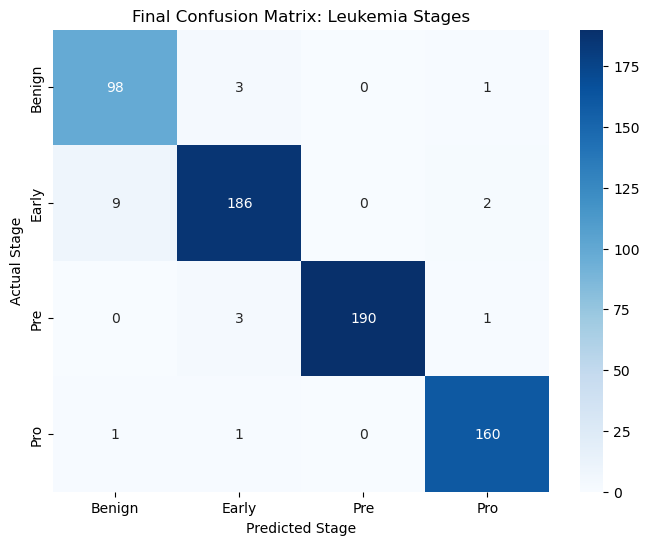

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Evaluate on the actual TEST folder
print("\n--- Running Final Evaluation on Test Set ---")
test_results = model.evaluate(test_gen)
print(f"Final Test Accuracy: {test_results[1]*100:.2f}%")

# 2. Get detailed predictions for the report
test_gen.reset()
Y_pred = model.predict(test_gen)
y_pred = np.argmax(Y_pred, axis=1)

# 3. Print the Classification Report
target_names = list(test_gen.class_indices.keys())
print(classification_report(test_gen.classes, y_pred, target_names=target_names))

# 4. Plot a Confusion Matrix (The visual proof)
cm = confusion_matrix(test_gen.classes, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=target_names, yticklabels=target_names)
plt.title('Final Confusion Matrix: Leukemia Stages')
plt.ylabel('Actual Stage')
plt.xlabel('Predicted Stage')
plt.show()

Loading model from best_leukemia_model.keras...
1/1 ━━━━━━━━━━━━━━━━━━━━ 23s 23s/step

--- Prediction Result ---
Result:     Pro
Confidence: 99.83%


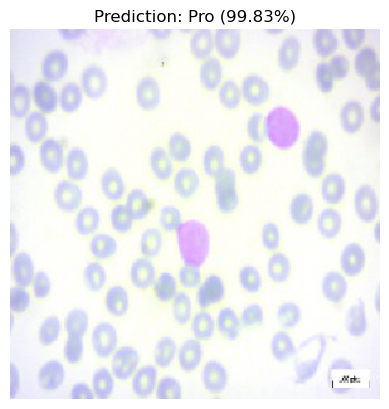

In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications.efficientnet import preprocess_input

path_to_your_image = r'leukemia_dataset_split\test\Pro\WBC-Malignant-Pro-061.jpg' 

IMG_SIZE = (300, 300) 

class_names = ['Benign', 'Early', 'Pre', 'Pro']

best_model_path = 'best_leukemia_model.keras'

print(f"Loading model from {best_model_path}...")
best_model = tf.keras.models.load_model(best_model_path)

try:
    # Load and resize image to 300x300
    img = load_img(path_to_your_image, target_size=IMG_SIZE)
    
    img_array = img_to_array(img)
    img_batch = np.expand_dims(img_array, axis=0)
    
    img_preprocessed = preprocess_input(img_batch)

    # --- 4. Make Prediction ---
    predictions = best_model.predict(img_preprocessed)
    
    # Get the index of the highest probability
    predicted_index = np.argmax(predictions[0])
    
    # Get the class name and confidence
    predicted_class = class_names[predicted_index]
    confidence = predictions[0][predicted_index] * 100
    
    # --- 5. Show Only Prediction Result ---
    print("\n--- Prediction Result ---")
    print(f"Result:     {predicted_class}")
    print(f"Confidence: {confidence:.2f}%")

    plt.imshow(img)
    plt.title(f"Prediction: {predicted_class} ({confidence:.2f}%)")
    plt.axis('off')
    plt.show()

except FileNotFoundError:
    print(f"Error: Image file not found at '{path_to_your_image}'")
except Exception as e:
    print(f"An error occurred: {e}")

In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import numpy as np
import tensorflow as tf

# 1. Load the model
path = "best_leukemia_model.keras"
model = tf.keras.models.load_model(path)

# 2. Reset generator and verify settings
val_gen.reset()
num_samples = val_gen.samples 

# 3. Predict exactly the number of samples available
# FIX: Wrap the calculation in int() to remove the 'float64' error
steps = int(np.ceil(num_samples / val_gen.batch_size))

# verbose=1 allows you to see the progress bar
preds = model.predict(val_gen, steps=steps, verbose=1)

# 4. Trim predictions to match the exact number of samples (649)
preds = preds[:num_samples]

y_pred = np.argmax(preds, axis=1)
y_true = val_gen.classes

# 5. Calculate Global Metrics
total_accuracy = accuracy_score(y_true, y_pred)
# 'weighted' is best for overall model performance across different stages
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')

print("\n" + "="*30)
print("--- Whole Model Performance ---")
print("="*30)
print(f"Total Accuracy:  {total_accuracy*100:.2f}%")
print(f"Total Precision: {precision*100:.2f}%")
print(f"Total Recall:    {recall*100:.2f}%")
print(f"Total F1-Score:  {f1*100:.2f}%")
print("="*30)

21/21 ━━━━━━━━━━━━━━━━━━━━ 119s 5s/step

--- Whole Model Performance ---
Total Accuracy:  96.92%
Total Precision: 96.99%
Total Recall:    96.92%
Total F1-Score:  96.92%


In [7]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import numpy as np
import tensorflow as tf

# 1. Load the model
model = tf.keras.models.load_model("best_leukemia_model.keras")

# 2. Use the TEST generator (The Final Exam)
test_gen.reset()
num_samples = test_gen.samples 

# 3. Predict on the unseen data
steps = int(np.ceil(num_samples / test_gen.batch_size))
preds = model.predict(test_gen, steps=steps, verbose=1)

# 4. Match the sample count exactly
preds = preds[:num_samples]
y_pred = np.argmax(preds, axis=1)
y_true = test_gen.classes

# 5. Calculate Final Global Metrics
total_accuracy = accuracy_score(y_true, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')

print("\n" + "="*30)
print("--- FINAL TEST SET PERFORMANCE ---")
print("="*30)
print(f"Final Accuracy:  {total_accuracy*100:.2f}%")
print(f"Final Precision: {precision*100:.2f}%")
print(f"Final Recall:    {recall*100:.2f}%")
print(f"Final F1-Score:  {f1*100:.2f}%")
print("="*30)

21/21 ━━━━━━━━━━━━━━━━━━━━ 119s 5s/step

--- FINAL TEST SET PERFORMANCE ---
Final Accuracy:  96.79%
Final Precision: 96.86%
Final Recall:    96.79%
Final F1-Score:  96.81%
